In [ ]:
!pip install -q torch torch-geometric pymatgen matgl dgl tqdm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 5.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 2.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.6/55.6 kB 3.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 74.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 829.1/829.1 kB 60.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 365.2/365.2 kB 36.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.6/8.6 MB 127.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.6/853.6 kB 59.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 125.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 123.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.0/140.0 kB 15.6 MB/s eta 0:00:00
   ━━━

In [ ]:
#!pip install emmet-core maggma

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import shutil
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import MessagePassing, global_mean_pool
import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch_geometric.data import Data, Dataset # To build graphs
from torch_geometric.loader import DataLoader # To load graphs
from torch.utils.data import Subset
from pymatgen.core import Structure, Element
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from tqdm import tqdm
import warnings
warnings.filterwarnings("ignore")
import gc
import time
import random
import math
from scipy import stats

#----------Verify GPU availability------------------------#
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
print(f"PyTorch version: {torch.__version__}")

Device: cuda
PyTorch version: 2.11.0+cu128


In [ ]:
# Ensure reproducibility
def set_seed(seed=2009):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed) # For multi-GPU

    # Force deterministic behavior in PyTorch
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    # Optional: Throw error if a non-deterministic operation is encountered
    torch.use_deterministic_algorithms(True)

    os.environ['PYTHONHASHSEED'] = str(seed)

set_seed(2009)

In [ ]:
df1 = pd.read_csv("/content/drive/MyDrive/Battery Research/battery_prop.csv",
                  names=["material_id","formula","band_gap"])
df1.head()

,material_id,formula,band_gap
0,mp-780192,Li5FeO4,2.6187
1,mp-1177943,Li2FeO2,3.1408
2,mp-887724,Li2FeO3,1.0267
3,mp-756155,Li6FeO4,2.7019
4,mp-1272755,Li2FeO2,3.0406


In [ ]:
# check if there is a cif file for every material_id in the csv file
cif_folder = "/content/drive/MyDrive/Battery Research/battery_materials_cifs"

cif_files = [f.replace(".cif","") for f in os.listdir(cif_folder) if f.endswith(".cif")]
csv_ids = df1["material_id"].tolist()

print(f"CIF files found:        {len(cif_files)}")
print(f"Compounds in CSV:       {len(csv_ids)}")
print()

# Find any mismatches
missing_cifs = [mid for mid in csv_ids if mid not in cif_files]
extra_cifs   = [mid for mid in cif_files if mid not in csv_ids]

print(f"In CSV but no CIF file: {len(missing_cifs)}")
print(f"CIF file but not in CSV:{len(extra_cifs)}")

CIF files found:        5169
Compounds in CSV:       5169

In CSV but no CIF file: 0
CIF file but not in CSV:0


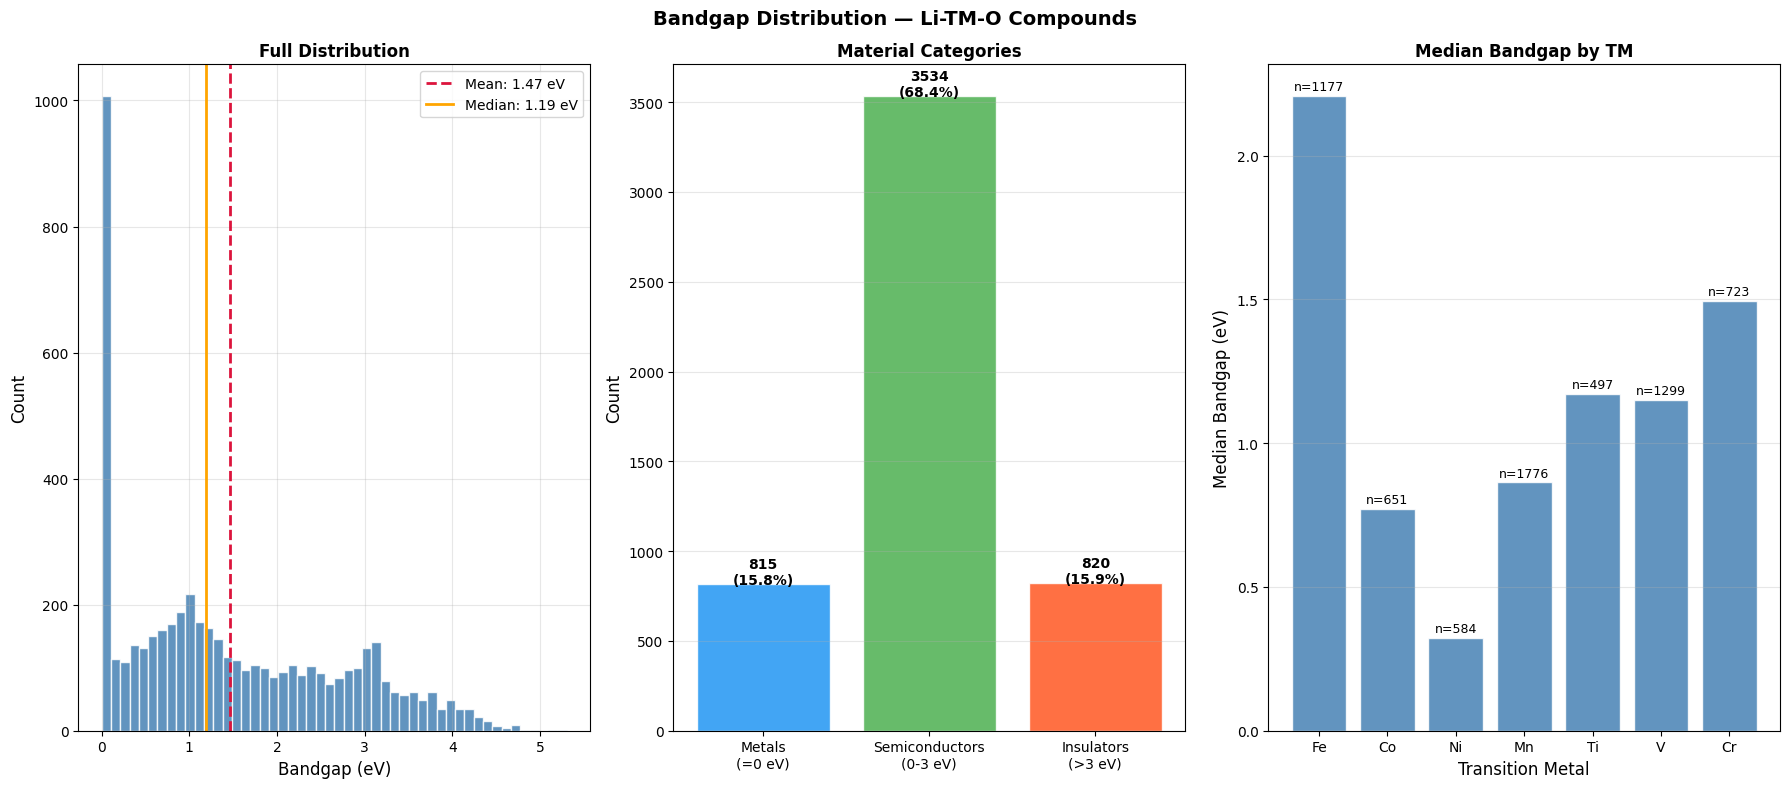

BANDGAP SUMMARY
Total compounds:    5169
Metals (bg=0):      815  (15.8%)
Semiconductors:     3534  (68.4%)
Insulators (bg>3):  820  (15.9%)
Min bandgap:        0.000 eV
Max bandgap:        5.304 eV
Mean bandgap:       1.469 eV
Std deviation:      1.243 eV


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 8))
fig.suptitle("Bandgap Distribution — Li-TM-O Compounds",
             fontsize=14, fontweight='bold')

# Full bandgap distribution
ax = axes[0]
ax.hist(df1['band_gap'], bins=50,
        color='steelblue', edgecolor='white', alpha=0.85)
ax.set_xlabel("Bandgap (eV)", fontsize=12)
ax.set_ylabel("Count", fontsize=12)
ax.set_title("Full Distribution", fontsize=12, fontweight='bold')
ax.axvline(df1['band_gap'].mean(), color='crimson',
           linewidth=2, linestyle='--',
           label=f"Mean: {df1['band_gap'].mean():.2f} eV")
ax.axvline(df1['band_gap'].median(), color='orange',
           linewidth=2, linestyle='-',
           label=f"Median: {df1['band_gap'].median():.2f} eV")
ax.legend(fontsize=10)
ax.grid(alpha=0.3)

# Metals vs semiconductors vs insulators
ax = axes[1]
metals       = df1[df1['band_gap'] == 0.0]
semiconductors = df1[(df1['band_gap'] > 0) & (df1['band_gap'] <= 3.0)]
insulators   = df1[df1['band_gap'] > 3.0]

categories = ['Metals\n(=0 eV)',
              'Semiconductors\n(0-3 eV)',
              'Insulators\n(>3 eV)']
counts = [len(metals), len(semiconductors), len(insulators)]
colors = ['#2196F3', '#4CAF50', '#FF5722']

bars = ax.bar(categories, counts, color=colors,
               edgecolor='white', alpha=0.85)

for bar, count in zip(bars, counts):
    pct = count / len(df1) * 100
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 1,
            f'{count}\n({pct:.1f}%)',
            ha='center', fontsize=10, fontweight='bold')

ax.set_ylabel("Count", fontsize=12)
ax.set_title("Material Categories", fontsize=12, fontweight='bold')
ax.grid(alpha=0.3, axis='y')

# Bandgap by transition metal
ax = axes[2]
tm_elements = ["Fe", "Co", "Ni", "Mn", "Ti", "V", "Cr"]
tm_medians  = []
tm_counts   = []

for tm in tm_elements:
    # Filter compounds containing this TM
    mask = df1['formula'].str.contains(tm, na=False)
    subset = df1[mask]['band_gap']
    tm_medians.append(subset.median() if len(subset) > 0 else 0)
    tm_counts.append(len(subset))

bars = ax.bar(tm_elements, tm_medians,
               color='steelblue', edgecolor='white', alpha=0.85)

for bar, count in zip(bars, tm_counts):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.02,
            f'n={count}', ha='center', fontsize=9)

ax.set_xlabel("Transition Metal", fontsize=12)
ax.set_ylabel("Median Bandgap (eV)", fontsize=12)
ax.set_title("Median Bandgap by TM", fontsize=12, fontweight='bold')
ax.grid(alpha=0.3, axis='y')

plt.tight_layout()
#plt.savefig("bandgap_distribution.png", dpi=300, bbox_inches='tight')
plt.show()

# Print summary
print("BANDGAP SUMMARY")
print("="*40)
print(f"Total compounds:    {len(df1)}")
print(f"Metals (bg=0):      {len(metals)}  ({len(metals)/len(df1)*100:.1f}%)")
print(f"Semiconductors:     {len(semiconductors)}  ({len(semiconductors)/len(df1)*100:.1f}%)")
print(f"Insulators (bg>3):  {len(insulators)}  ({len(insulators)/len(df1)*100:.1f}%)")
print(f"Min bandgap:        {df1['band_gap'].min():.3f} eV")
print(f"Max bandgap:        {df1['band_gap'].max():.3f} eV")
print(f"Mean bandgap:       {df1['band_gap'].mean():.3f} eV")
print(f"Std deviation:      {df1['band_gap'].std():.3f} eV")

In [ ]:
# Build a numerical feature vector to encode the features of each node in a material
def get_atom_features(element_symbol):
  try:
    elem = Element(element_symbol)
  except Exception:
    # if element is unknown return 0
    # Return the 10 base atomic features.
    # Oxidation state is added later in cif_to_graph().
    return [0.0] * 19 # *11 to match feature vector shape

  def safe_get(value, default=0.0):
    # Return value or default of zero if value is None
    try:
      if value is None:
        return default
      if isinstance(value, tuple):
        value = value[0]
      return float(value)
    except:
      return default

  node_features = [
      safe_get(elem.Z), # Atomic number
      safe_get(elem.row), # period in which the element belongs to in the periodic table
      safe_get(elem.group), # group in which the element belongs to in the periodic table
      safe_get(elem.atomic_radius), # atomic radius
      safe_get(elem.X), # electronegativity
      safe_get(elem.ionization_energy), #ionization energy
      safe_get(elem.mendeleev_no), #mendeleev number
      safe_get(elem.electron_affinity), #electron affinity
      safe_get(elem.molar_volume)
  ]

  # count of electrons in each orbital
  config = elem.full_electronic_structure
  s_count = sum(count for n, orb, count in config if orb == "s")
  p_count = sum(count for n, orb, count in config if orb == "p")
  d_count = sum(count for n, orb, count in config if orb == "d")
  f_count = sum(count for n, orb, count in config if orb == "f")
  node_features.extend([s_count, p_count, d_count, f_count])

  # Transition metal flag
  Tm_elements = {"Fe","Co","Ni","Mn","Ti","V","Cr"}
  node_features.append(1.0 if element_symbol in Tm_elements else 0.0)

  # s,p,d,f block - one-hot vector
  block_dict = {
      's': [1.0, 0.0, 0.0, 0.0],
      'p': [0.0, 1.0, 0.0, 0.0],
      'd': [0.0, 0.0, 1.0, 0.0],
      'f': [0.0, 0.0, 0.0, 1.0]
  }
  block_vec = block_dict.get(elem.block, [0.0, 0.0, 0.0, 0.0])
  node_features.extend(block_vec)

  return node_features


# Bond Features
# The bond length measured in angstroms is converted to 41 numbers via gaussian expansion
def gaussian_expansion(distance, dmin=0.0, dmax=8.0, step=0.2):
  filter_centers = np.arange(dmin, dmax + step, step)
  expanded = np.exp(-(distance - filter_centers) ** 2 / (step ** 2))
  return expanded

# Main conversion function [cif to graph]
# This function does three things
# 1. Load the structure and returns the position of the number of atoms in the compound
def cif_to_graph(cif_path, cutoff_radius=8.0, max_neighbours=12):
  try:
    structure = Structure.from_file(cif_path)
    # Guess oxidation states from the crystal chemistry
    try:
        structure.add_oxidation_state_by_guess()
    except Exception:
        print(f"Warning: Could not assign oxidation states for {cif_path}")

  except Exception as e:
    print(f"Failed to Load {cif_path}: {e}")
    return None

  # 2. Build node features
  atom_features = []
  for site in structure:
    # Get elemental symbol
    element = site.specie.symbol
    # Existing 10 features
    features = get_atom_features(element)
    try:
        ox_state = float(site.specie.oxi_state)
    except Exception:
        ox_state = 0.0

    features.append(ox_state)
    atom_features.append(features)


  # Shape of feature vector (num of atoms, num of atom_features)
  x = torch.tensor(atom_features, dtype=torch.float)

  # Build edges (bond features)
  all_neighbours = structure.get_all_neighbors(cutoff_radius, include_index=True)
  edge_src = []  # source atom index
  edge_dst = []  # destination atom index
  edge_features = [] # bond distance features

  for atom_idx, neighbours in enumerate(all_neighbours):
    # safety check for isolated atom within the cutoff radius
    if len(neighbours) == 0:
      continue

    neighbours = sorted(neighbours, key=lambda x: x[1])[:max_neighbours] # Sort by distance

    for neighbour in neighbours:
      neighbour_site, distance, neighbour_idx, image = neighbour
      # Add edge: atom_idx -> neighbour_atom_idx
      edge_src.append(atom_idx)
      edge_dst.append(neighbour_idx)
      edge_features.append(gaussian_expansion(distance))

  # Handle cases where no edges were found
  if len(edge_src) == 0:
    return None

  # shape of bond edges
  edge_index = torch.tensor([edge_src, edge_dst], dtype=torch.long)

  # shape of bond attributes
  edge_attr = torch.tensor(np.array(edge_features), dtype=torch.float)

  return x, edge_index, edge_attr

In [ ]:
class LiTMODataset(Dataset):
    """
    Disk-based dataset for Li-TM-O crystal graphs.
    Processes one CIF at a time — RAM stays flat throughout.
    Saves a manifest CSV after processing for GroupShuffleSplit.
    """

    def __init__(self, df, cif_dir, target_col="band_gap", cutoff_radius=8.0, max_neighbours=12):
        self.df            = df.reset_index(drop=True)
        self.cif_dir       = cif_dir
        self.target_col    = target_col
        self.cutoff_radius = cutoff_radius
        self.max_neighbours = max_neighbours
        super(LiTMODataset, self).__init__(root="/content/drive/MyDrive/Battery Research/battery_materials_graph")

    @property
    def raw_file_names(self):
        return []

    @property
    def processed_file_names(self):
        # One small file per compound — never loaded all at once
        return [f"graph_{i}.pt" for i in range(len(self.df))]

    def process(self):
        df = self.df

        os.makedirs(self.processed_dir, exist_ok=True)

        print(f"Converting {len(df)} CIF files to graphs...")
        print(f"Cutoff radius: {self.cutoff_radius} Å")
        print()

        failed        = 0
        succeeded     = 0
        manifest_rows = []

        for i, row in tqdm(df.iterrows(), total=len(df)):

            material_id = row["material_id"]
            cif_path    = os.path.join(self.cif_dir, f"{material_id}.cif")
            save_path   = os.path.join(self.processed_dir, f"graph_{i}.pt")

            # ── Validate band gap value ───────────────────────────────────
            try:
                band_gap = float(row[self.target_col])
            except:
                failed += 1
                continue

            # ── Process only if graph does not already exist ──────────────
            if not os.path.exists(save_path):

                if not os.path.exists(cif_path):
                    failed += 1
                    continue

                result = cif_to_graph(cif_path, self.cutoff_radius, self.max_neighbours)

                if result is None:
                    failed += 1
                    continue

                x, edge_index, edge_attr = result

                graph = Data(
                    x          = x,
                    edge_index = edge_index,
                    edge_attr  = edge_attr,
                    y          = torch.tensor([[band_gap]], dtype=torch.float),
                    material_id = material_id
                )

                # Save immediately — free RAM right away
                torch.save(graph, save_path)
                del graph, x, edge_index, edge_attr, result
                gc.collect()

            # ── Add to manifest regardless of whether just processed
            #    or already existed from a previous run ────────────────────
            manifest_rows.append({
                "index":       i,
                "material_id": material_id,
                "band_gap":    band_gap,
                "formula":     row.get("formula", ""),
            })

            succeeded += 1

        print(f"\nConversion complete:")
        print(f"  Succeeded:    {succeeded}")
        print(f"  Failed:       {failed}")
        print(f"  Success rate: {succeeded/(succeeded+failed)*100:.1f}%")

        # ── Save manifest CSV ─────────────────────────────────────────────
        # This small file is all you need for GroupShuffleSplit
        # It maps every graph index to its formula and band gap
        manifest = pd.DataFrame(manifest_rows)
        manifest_path = os.path.join(self.processed_dir, "manifest.csv")
        manifest.to_csv(manifest_path, index=False)
        print(f"\nManifest saved to: {manifest_path}")
        print(manifest.head())

    def len(self):
        return len(self.df)

    def get(self, idx):
        # Load ONE graph from disk when the DataLoader asks for it
        return torch.load(
            os.path.join(self.processed_dir, f"graph_{idx}.pt")
        )

    def __repr__(self):
        return f"LiTMODataset({len(self)} compounds)"

In [ ]:
print("Building dataset...")
print("====================")
dataset = LiTMODataset(
    df = df1,
    cif_dir = "/content/drive/MyDrive/Battery Research/battery_materials_cifs",
    target_col = "band_gap",
    cutoff_radius = 8.0,
    max_neighbours = 12
)
print(f"Dataset Ready: {dataset}")

Building dataset...


Processing...


Converting 5169 CIF files to graphs...
Cutoff radius: 8.0 Å



100%|██████████| 5169/5169 [59:59<00:00,  1.44it/s]


Conversion complete:
  Succeeded:    5169
  Failed:       0
  Success rate: 100.0%

Manifest saved to: /content/drive/MyDrive/Battery Research/battery_materials_graph/processed/manifest.csv
   index material_id  band_gap  formula
0      0   mp-780192    2.6187  Li5FeO4
1      1  mp-1177943    3.1408  Li2FeO2
2      2   mp-887724    1.0267  Li2FeO3
3      3   mp-756155    2.7019  Li6FeO4
4      4  mp-1272755    3.0406  Li2FeO2
Dataset Ready: LiTMODataset(5169 compounds)



Done!


In [ ]:
# copy graphs files to disk
drive_processed_path = "/content/drive/MyDrive/Battery Research/battery_materials_graph/processed"

# Define where they are going (Local Colab Disk)
local_root_path = "/content/local_battery_graph"
local_processed_path = os.path.join(local_root_path, "processed")

# Copy the files
if not os.path.exists(local_processed_path):
    print("Copying files to local Colab storage...")
    shutil.copytree(drive_processed_path, local_processed_path)
    print("Copy complete!")
else:
    print("Files are already copied to the local disk!")

Copying files to local Colab storage...
Copy complete!


In [ ]:
# Groupshufflesplit the data
manifest = pd.read_csv("/content/local_battery_graph/processed/manifest.csv")
groups = manifest["formula"].values
gss = GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=42)
train_idx, test_idx = next(gss.split(manifest, groups=groups))

print(f"Train data: {len(train_idx)} compounds")
print(f"Test data:  {len(test_idx)} compounds")

Train data: 4653 compounds
Test data:  516 compounds


In [ ]:
# Verify if there is data leakage
train_formulas = set(manifest.iloc[train_idx]["formula"].values)
test_formulas = set(manifest.iloc[test_idx]["formula"].values)

train_test_overlap = train_formulas.intersection(test_formulas)
print(f"Train/test overlap: {len(train_test_overlap)} compounds")

Train/test overlap: 0 compounds


In [ ]:
train_manifest = manifest.iloc[train_idx].reset_index(drop=True)
test_manifest = manifest.iloc[test_idx].reset_index(drop=True)

#save to csv
#train_manifest.to_csv("/content/drive/MyDrive/Battery Research/battery_materials_graph/processed/train_manifest.csv", index=False)
#test_manifest.to_csv("/content/drive/MyDrive/Battery Research/battery_materials_graph/processed/test_manifest.csv", index=False)

In [ ]:
#Access the graphs using the split
class PointToGraphs(Dataset):
  #use the index to locate the graphs
  def __init__(self, manifest, processed_dir):
    self.manifest = manifest.reset_index(drop=True)
    self.graph_dir = processed_dir
    super(PointToGraphs, self).__init__(root="/content/local_battery_graph")

  # Return empty list as the graphs have already been processed and saved to disk
  @property
  def raw_file_names(self):
    return []

  @property
  def processed_file_names(self):
    return []

  def len(self):
    return len(self.manifest)

  def get(self, idx):
    graph_idx = self.manifest.iloc[idx]["index"]
    return torch.load(os.path.join(self.graph_dir, f"graph_{int(graph_idx)}.pt"), weights_only=False)


def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)


train_data = PointToGraphs(train_manifest, "/content/local_battery_graph/processed/")
test_data = PointToGraphs(test_manifest, "/content/local_battery_graph/processed/")

BATCH_SIZE = 64


# Apply this to your DataLoaders
g = torch.Generator()
g.manual_seed(2009)


train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, generator=g)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False)

print(f"Train batches: {len(train_loader)}")
print(f"Test batches:  {len(test_loader)}")

Train batches: 73
Test batches:  9


In [ ]:
def compute_node_stats(loader):
    print("Computing node feature statistics from training set...")
    all_x = []

    # Gather all atom features from the training set
    for batch in loader:
        all_x.append(batch.x)

    # Concatenate into one massive 2D tensor [Total_Atoms, 20]
    all_x = torch.cat(all_x, dim=0)

    # Calculate mean and std for each of the 11 columns
    node_mean = torch.mean(all_x, dim=0)
    node_std = torch.std(all_x, dim=0)

    # If a feature is identical for all atoms (std = 0),
    # replace the 0 with 1.0 to prevent dividing by zero and causing NaNs.
    node_std[node_std == 0] = 1.0

    return node_mean, node_std

# Run the function and move the tensors to your GPU/CPU
node_mean, node_std = compute_node_stats(train_loader)
node_mean = node_mean.to(device)
node_std = node_std.to(device)

print(f"Node Mean: {node_mean}")
print(f"Node Std:  {node_std}")

Computing node feature statistics from training set...
Node Mean: tensor([1.0592e+01, 2.4033e+00, 1.1913e+01, 8.9755e-01, 2.6342e+00, 1.0977e+01,
        7.9046e+01, 1.0800e+00, 1.4969e+01, 4.6193e+00, 5.0576e+00, 8.9928e-01,
        1.5385e-02, 1.4102e-01, 1.7362e-01, 6.7985e-01, 1.4524e-01, 1.2963e-03,
        2.9745e-10], device='cuda:0')
Node Std:  tensor([ 7.9523,  0.7899,  5.9529,  0.3869,  0.9989,  3.4261, 33.0030,  0.5895,
         4.1588,  1.6763,  3.9925,  2.6088,  0.4642,  0.3480,  0.3788,  0.4665,
         0.3523,  0.0360,  2.5099], device='cuda:0')


In [ ]:
# Message Passing mechanism
class CGCNNConv(MessagePassing):
  def __init__(self, node_dim, edge_dim, hidden_dim, dropout=0.25):
    """
    node_dim: size of atom features (64)
    edge_dim: size of bond features (41)
    hidden_dim: size of hidden representations (64)
    """
    super(CGCNNConv, self).__init__(aggr="mean") #aggregrate message from neighbouring atoms by summing

    # Gate Network
    # Decides how important to trust the information from neighbouring atoms
    # Input: current atom + neighbour atom + bond between them
    # Output: a number between 0 and 1 (sigmoid function is applied)
    self.gate = nn.Sequential(
        nn.Linear((2 * node_dim) + edge_dim, hidden_dim),
        nn.BatchNorm1d(hidden_dim),
        nn.Sigmoid()
    )
    # Update Network
    # Extract what information to take from the neighbour
    self.update_net = nn.Sequential(
        nn.Linear((2 * node_dim) + edge_dim, hidden_dim),
        nn.BatchNorm1d(hidden_dim),
        nn.Softplus()
    )
    # Output projection
    # projects aggregated messages back to node_dim
    self.output = nn.Linear(hidden_dim, node_dim)
    self.bn = nn.BatchNorm1d(node_dim)
    self.dropout = nn.Dropout(p=dropout)

  def forward(self, x, edge_index, edge_attr):
    # Run one round of message passing
    # propagate() handles the message passing loop, it calls the message() for every bond, then aggregates, then calls update()
    return self.propagate(edge_index, x=x, edge_attr=edge_attr)

  def message(self, x_i, x_j, edge_attr):
    # Define what message each neighbour sends
    # Uses the gate, and update_net to ensure message received from neignbouring atoms is important
    combined = torch.cat([x_i, x_j, edge_attr], dim=-1)
    gate = self.gate(combined)
    update = self.update_net(combined)
    return gate * update

  def update(self, aggr_out, x):
    #update each atom after collecting all messages
    #aggr_out: sum of all recieved messages
    #x: atom features before this round of message passing
    # Add old features with new ones to prevent the atom from forgetting its identity
    out = self.output(aggr_out)
    out = self.bn(out)  # out = self.bn(out + x)
    out = out + self.dropout(x)
    return F.softplus(out)


In [ ]:
# Full CGCNN Network
class CGCNN(nn.Module):
  """Complete CGCNN network for bandgap prediction
  It takes a crystal graph as input, runs message passing,
  pools to crystal level and predicts bandgap
  """
  def __init__(self, node_features, edge_features, hidden_dim=32, n_conv=2, n_fc=2, dropout=0.1):
    super(CGCNN, self).__init__()

    # Atom embedding
    self.embedding = nn.Sequential(
        nn.Linear(node_features, hidden_dim),
        nn.BatchNorm1d(hidden_dim),
        nn.Softplus()
    )
    # Message passing layers
    # Number of message passing rounds
    # creates n_conv independent conv layers, each has its own learnable weight
    self.conv_layers = nn.ModuleList([
        CGCNNConv(hidden_dim, edge_features, hidden_dim) for _ in range(n_conv)
    ])

    # Fully connected layers
    fc_layers = []
    input_dim = hidden_dim

    for i in range(n_fc):
      output_dim = hidden_dim // (2**i)
      fc_layers.extend([
          nn.Linear(input_dim, output_dim),
          nn.BatchNorm1d(output_dim),
          nn.Softplus(),
          nn.Dropout(p=dropout)
      ])
      input_dim = output_dim
    self.fc_layers = nn.Sequential(*fc_layers)

    # Output (Bandgap)
    self.output = nn.Linear(input_dim, 1)

  def forward(self, data):
    # Full forward pass through the network
    x, edge_index, edge_attr, batch = data.x, data.edge_index, data.edge_attr, data.batch
    # Embed raw atom features
    x = self.embedding(x)
    # Message passing rounds: Each round, each atoms gets to learn about its neighbours. x shape stays the same but now richer with info
    for conv in self.conv_layers:
      x = conv(x, edge_index, edge_attr)
    # Global pooling
    # Average all atom vectors per crystal
    # Batch tells pyG which atoms belong to which crystal
    crystal_vec = global_mean_pool(x, batch)
    out = self.fc_layers(crystal_vec)
    # Predicted bandgap
    return self.output(out).squeeze(-1)


In [ ]:
#Instantiate the model
graph_node = train_data[0]
node_ft = graph_node.x.shape[1]
edge_ft = graph_node.edge_attr.shape[1]

print(f"Node features: {node_ft}")
print(f"Edge features: {edge_ft}")
print(f"Graph bandgap: {graph_node.y.item()} eV")

bg_model = CGCNN(node_features=node_ft, edge_features=edge_ft, hidden_dim=64, n_conv=3, n_fc=3, dropout=0.25).to(device)
print(f"Model ready on: {device}")
print(f"Parameters: {sum(p.numel() for p in bg_model.parameters()):,}")

Node features: 19
Edge features: 41
Graph bandgap: 2.6187000274658203 eV
Model ready on: cuda
Parameters: 87,329


In [ ]:
# Loss functiom
criterion = nn.L1Loss()
# Optimizer
optimizer = optim.AdamW(bg_model.parameters(), lr=0.0005, weight_decay=1e-3) #weight decay: prevents weight from growing too large
# Learning rate scheduler - Reduce learning rate when model stops improving
scheduler = ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=20)

print("Loss function: MAE (L1Loss)")
print("Optimiser:AdamW")
print("Scheduler:ReduceLROnPlateau")

Loss function: MAE (L1Loss)
Optimiser:AdamW
Scheduler:ReduceLROnPlateau


In [ ]:
mean_val = train_manifest["band_gap"].mean()
std_val = train_manifest["band_gap"].std()
print(f"Mean: {mean_val:.4f} eV, Std Dev: {std_val:.4f} eV")

Mean: 1.4641 eV, Std Dev: 1.2409 eV


In [ ]:
def train_one_epoch(model, loader, optimizer, criterion, device, mean, std, node_mean, node_std):
  model.train()
  all_train_preds = []
  all_train_targets = []
  total_loss = 0
  n_batches = 0

  for batch in loader:
    batch = batch.to(device)

    # scale node features
    batch.x = (batch.x - node_mean) / node_std

    # scale targets
    scaled_targets = (batch.y.view(-1) - mean) / std
    predictions = model(batch).view(-1)

    loss = criterion(predictions, scaled_targets)

    # Backward Propagation
    optimizer.zero_grad()
    loss.backward()
    #prevent exploding gradients
    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=0.5)
    #update weights
    optimizer.step()
    total_loss += loss.item()
    n_batches += 1

    # unscale for metrics calculation
    train_preds = (predictions.detach() * std) + mean
    train_targets = batch.y.view(-1)

    all_train_preds.extend(train_preds.cpu().numpy().flatten())
    all_train_targets.extend(train_targets.cpu().numpy().flatten())

  all_train_preds = np.array(all_train_preds)
  all_train_targets = np.array(all_train_targets)

  train_mae = mean_absolute_error(all_train_targets, all_train_preds)
  train_mse = mean_squared_error(all_train_targets, all_train_preds)
  train_r2 = r2_score(all_train_targets, all_train_preds)
  avg_loss = total_loss / n_batches

  return avg_loss, train_mae, train_mse, train_r2


def evaluate(model, loader, criterion, device, mean, std, node_mean, node_std):
  model.eval()
  all_test_preds = []
  all_test_targets = []
  total_loss = 0
  n_batches = 0

  with torch.no_grad():
    for batch in loader:
      batch = batch.to(device)
      #scale node features in test set
      batch.x = (batch.x - node_mean) / node_std

      scaled_preds = model(batch).view(-1)
      #scale targets in test set
      scaled_targets = (batch.y.view(-1) - mean) / std

      # calculate loss on scaled values for consistency
      loss = criterion(scaled_preds, scaled_targets)
      total_loss += loss.item()
      n_batches += 1

      # Unscale for metrics calculation
      test_preds = (scaled_preds * std) + mean
      test_targets = batch.y.view(-1)

      all_test_preds.extend(test_preds.cpu().numpy().flatten())
      all_test_targets.extend(test_targets.cpu().numpy().flatten())

  all_test_preds = np.array(all_test_preds)
  all_test_targets = np.array(all_test_targets)

  test_mae = mean_absolute_error(all_test_targets, all_test_preds)
  test_mse = mean_squared_error(all_test_targets, all_test_preds)
  test_r2 = r2_score(all_test_targets, all_test_preds)
  avg_loss = total_loss / n_batches

  return avg_loss, test_mae, test_mse, test_r2, all_test_targets, all_test_preds

In [ ]:
# Training Loop
n_epochs = 200
best_val_loss = float("inf")
best_model_path = "best_cgcnn_bandgap.pt"
patience_counter = 0
early_stopping = 30

#Track metrics for plotting
history = {
    "train_loss": [],
    "test_loss": [],
    "train_mae": [],
    "test_mae": [],
    "train_mse": [],
    "test_mse": [],
    "train_r2": [],
    "test_r2": []
}

print("Training CGCNN Model for Bandgap prediction...")
print("="*88)
print(f"{'Epoch':>5} | {'Train MAE':>9} {'Test MAE':>9} | {'Train MSE':>9} {'Test MSE':>9} | {'Train R²':>8} {'Test R²':>8} | {'Time':>6}")
print("="*88)

for epoch in range(1, n_epochs+1):
  start = time.time()
  # Train model
  train_loss, train_mae, train_mse, train_r2 = train_one_epoch(bg_model, train_loader, optimizer, criterion, device, mean_val, std_val, node_mean, node_std)
  # Evaluate model
  test_loss, test_mae, test_mse, test_r2, test_preds, test_targets = evaluate(bg_model, test_loader, criterion, device, mean_val, std_val, node_mean, node_std)
  # Update scheduler
  scheduler.step(test_loss)
  # save history
  history["train_loss"].append(train_loss)
  history["test_loss"].append(test_loss)
  history["train_mae"].append(train_mae)
  history["test_mae"].append(test_mae)
  history["train_mse"].append(train_mse)
  history["test_mse"].append(test_mse)
  history["train_r2"].append(train_r2)
  history["test_r2"].append(test_r2)

  epoch_time = time.time() - start

  if epoch % 10 == 0 or epoch == 1:
    print(f"{epoch:>5} | {train_mae:>9.4f} {test_mae:>9.4f} | "
          f"{train_mse:>9.4f} {test_mse:>9.4f} | "
          f"{train_r2:>8.4f} {test_r2:>8.4f} | {epoch_time:>5.1f}")
  if test_loss < best_val_loss:
    best_val_loss = test_loss
    patience_counter = 0
    torch.save({
        "epoch": epoch,
        "model_state_dict": bg_model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "test_loss": test_loss,
        "test_mae": test_mae,
        "test_mse": test_mse,
        "test_r2": test_r2
    }, best_model_path)
  else:
    patience_counter += 1


  if patience_counter >= early_stopping:
    print(f"\nEarly stopping at epoch {epoch}")
    break

print("=" * 65)
print("Training complete")

Training CGCNN Model for Bandgap prediction...
Epoch | Train MAE  Test MAE | Train MSE  Test MSE | Train R²  Test R² |   Time
    1 |    0.4569    0.4618 |    0.3990    0.4089 |   0.7408   0.7439 |   5.8
   10 |    0.4496    0.4709 |    0.3867    0.4318 |   0.7488   0.7295 |   5.9
   20 |    0.4481    0.4507 |    0.3860    0.4177 |   0.7493   0.7383 |   6.5
   30 |    0.4356    0.4689 |    0.3690    0.4236 |   0.7603   0.7346 |   5.8
   40 |    0.4369    0.4381 |    0.3695    0.3619 |   0.7600   0.7733 |   6.5
   50 |    0.4327    0.4608 |    0.3756    0.4441 |   0.7560   0.7218 |   5.8
   60 |    0.4142    0.4554 |    0.3330    0.3884 |   0.7837   0.7567 |   6.6
   70 |    0.4117    0.4734 |    0.3276    0.3986 |   0.7872   0.7503 |   5.8
   80 |    0.4009    0.4646 |    0.3070    0.4112 |   0.8005   0.7424 |   6.5
   90 |    0.3803    0.4677 |    0.2848    0.3962 |   0.8150   0.7518 |   5.8

Early stopping at epoch 94
Training complete


In [ ]:
# Final prediction on Train set
checkpoint = torch.load(best_model_path)
bg_model.load_state_dict(checkpoint["model_state_dict"])
bg_model.eval()
train_loss, train_mae, train_mse, train_r2, train_preds, train_targets = evaluate(bg_model, train_loader, criterion, device, mean_val, std_val, node_mean, node_std)

# Print model results
print(f"Train MAE: {train_mae:.4f} eV")
print(f"Train MSE: {train_mse:.4f} eV")
print(f"Train R²: {train_r2:.4f}")

Train MAE: 0.2730 eV
Train MSE: 0.1881 eV
Train R²: 0.8778


In [ ]:
# Final prediction on Test set
checkpoint = torch.load(best_model_path)
bg_model.load_state_dict(checkpoint["model_state_dict"])
bg_model.eval()
test_loss, test_mae, test_mse, test_r2, test_preds, test_targets = evaluate(bg_model, test_loader, criterion, device, mean_val, std_val, node_mean, node_std)

# Print model results
print(f"Test MAE: {test_mae:.4f} eV")
print(f"Test MSE: {test_mse:.4f} eV")
print(f"Test R²: {test_r2:.4f}")

Test MAE: 0.4355 eV
Test MSE: 0.3670 eV
Test R²: 0.7701


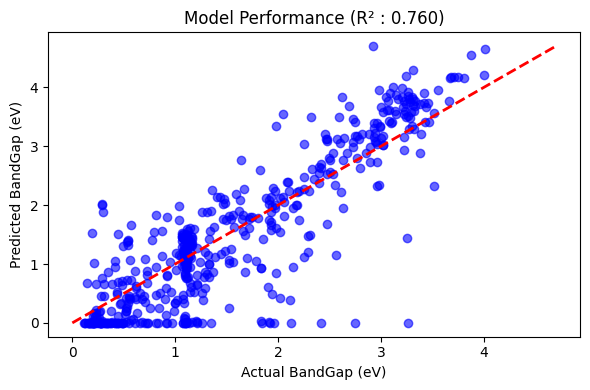

In [ ]:
# Visualize targets and predictions
plt.figure(figsize=(6,4))

plt.scatter(test_targets, test_preds, alpha=0.6, color="blue")
# line of perfect prediction
min_val = min(test_targets.min(), test_preds.min())
max_val = max(test_targets.max(), test_preds.max())
plt.plot([min_val, max_val], [min_val, max_val], "r--", lw=2)

plt.xlabel("Actual BandGap (eV)")
plt.ylabel("Predicted BandGap (eV)")
plt.title(f"Model Performance (R² : {test_r2:.3f})")
plt.tight_layout()
plt.show()